In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
df=pd.read_csv("../data/Dataset- Superstore.csv",parse_dates=['Order Date', 'Ship Date'])
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,2014-01-21,2014-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


In [7]:
year_month=df['Order Date'].dt.to_period('M').dt.to_timestamp()#.strftime('%Y-%m')
month_names=df.groupby(year_month)[['Sales','Profit']].sum().reset_index()
monthly_fig=px.line(month_names,x="Order Date",y=['Sales','Profit'],title="Monthly Sales & Profit Trend")
monthly_fig.update_xaxes(
    tickmode="linear",
    dtick="M1",
    tickangle=45)
# month_names

In [67]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

CSV encoding is correct and DataFrame is loaded Successfully

In [68]:
df.head()
df.sample(5)
df.tail() 

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,2014/01/21,2014/01/23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2017-121258,2017/02/26,2017/03/03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2017-121258,2017/02/26,2017/03/03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2017-121258,2017/02/26,2017/03/03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2017-119914,2017/05/04,2017/05/09,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


Inspected initail,last and random rows this ensures that data is in correct format and correctly loaded

In [69]:
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

Data is divided into four groups:Identifier,Numerical,Categorical and Dates

In [70]:
col=["Category","Sub-Category","Region","Segment","Ship Mode"]
for items in col: 
    print("Unique Items:",df[items].unique())
    print("Count:",df[items].nunique())

Unique Items: <StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str
Count: 3
Unique Items: <StringArray>
[  'Bookcases',      'Chairs',      'Labels',      'Tables',     'Storage',
 'Furnishings',         'Art',      'Phones',     'Binders',  'Appliances',
       'Paper', 'Accessories',   'Envelopes',   'Fasteners',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str
Count: 17
Unique Items: <StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str
Count: 4
Unique Items: <StringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str
Count: 3
Unique Items: <StringArray>
['Second Class', 'Standard Class', 'First Class', 'Same Day']
Length: 4, dtype: str
Count: 4


In [71]:
df.isnull().sum()
df.duplicated().sum()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [72]:
df.nsmallest(5,"Profit")

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
7772,7773,CA-2016-108196,2016/11/25,2016/12/02,Standard Class,CS-12505,Cindy Stewart,Consumer,United States,Lancaster,...,43130,East,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.9780
683,684,US-2017-168116,2017/11/04,2017/11/04,Same Day,GT-14635,Grant Thornton,Corporate,United States,Burlington,...,27217,South,TEC-MA-10004125,Technology,Machines,Cubify CubeX 3D Printer Triple Head Print,7999.980,4,0.5,-3839.9904
9774,9775,CA-2014-169019,2014/07/26,2014/07/30,Standard Class,LF-17185,Luke Foster,Consumer,United States,San Antonio,...,78207,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,2177.584,8,0.8,-3701.8928
3011,3012,CA-2017-134845,2017/04/17,2017/04/23,Standard Class,SR-20425,Sharelle Roach,Home Office,United States,Louisville,...,80027,West,TEC-MA-10000822,Technology,Machines,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,0.7,-3399.9800
4991,4992,US-2017-122714,2017/12/07,2017/12/13,Standard Class,HG-14965,Henry Goldwyn,Corporate,United States,Chicago,...,60653,Central,OFF-BI-10001120,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,1889.990,5,0.8,-2929.4845


Dataset have 21columns named:sales,profit,discount,city,state etc with 4 regions(east,west,north and south) with 3 main product categories and dataset have 0 null and duplicate value,few outliers found in sales and profit columns found,profits column have negative values.

# Data Cleaning

part 2

In [73]:
df.isnull().sum()
df.duplicated(subset="Order ID").sum()
df.duplicated(subset="Product ID").sum()

np.int64(8132)

There is no duplicates in dataset, Order ID and Product ID have massive duplicates but its a normal thing single order has many products or same or many quantity

In [74]:
df.columns   #all column names are valid and cleaned

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [75]:
df[["Order Date","Ship Date"]]=df[["Order Date","Ship Date"]].apply(pd.to_datetime)  #rest of all dtypes are correct
df.min()

Row ID                                                           1
Order ID                                            CA-2014-100006
Order Date                                     2014-01-03 00:00:00
Ship Date                                      2014-01-07 00:00:00
Ship Mode                                              First Class
Customer ID                                               AA-10315
Customer Name                                        Aaron Bergman
Segment                                                   Consumer
Country                                              United States
City                                                      Aberdeen
State                                                      Alabama
Postal Code                                                   1040
Region                                                     Central
Product ID                                         FUR-BO-10000112
Category                                                 Furni

Dataset doesn't contain invalid sales,quantity,discount,categories,or invalid dates.Negative profit values are present.

In [76]:
df[["Sales","Profit","Quantity","Discount"]].describe().round(1)

,Sales,Profit,Quantity,Discount
count,9994.0,9994.0,9994.0,9994.0
mean,229.9,28.7,3.8,0.2
std,623.2,234.3,2.2,0.2
min,0.4,-6600.0,1.0,0.0
25%,17.3,1.7,2.0,0.0
50%,54.5,8.7,3.0,0.2
75%,209.9,29.4,5.0,0.2
max,22638.5,8400.0,14.0,0.8


In [77]:
data=["Sales","Profit","Quantity","Discount"]
for i in range(len(data)):
    arr=df[data[i]].to_numpy()
    q1,q3=np.quantile(arr,[0.25,0.75])
    IQR=q3-q1
    lower=q1-(1.5*IQR)
    upper=q3+(1.5*IQR)
    print(f"{data[i]}: Lower={lower} , Upper={upper}")

Sales: Lower=-271.71000000000004 , Upper=498.93
Profit: Lower=-39.724125 , Upper=70.816875
Quantity: Lower=-2.5 , Upper=9.5
Discount: Lower=-0.30000000000000004 , Upper=0.5


In [78]:
#profit outlier
q1, q3 = df["Profit"].quantile([0.25, 0.75])
iqr = q3 - q1
plower = q1 - 1.5 * iqr
pupper = q3 + 1.5 * iqr
profit_outlier=df[(df["Profit"]<plower) | (df["Profit"]>pupper)][["Category","Sub-Category","Product Name"]]
profit_outlier
#Sales outlier
q1, q3 = df["Sales"].quantile([0.25, 0.75])
iqr = q3 - q1
slower = q1 - 1.5 * iqr
supper = q3 + 1.5 * iqr
sales_outlier=df[(df["Sales"]<slower) | (df["Sales"]>supper)][["Category","Sub-Category","Product Name"]]
sales_outlier

,Category,Sub-Category,Product Name
1,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,..."
3,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table
7,Technology,Phones,Mitel 5320 IP Phone VoIP phone
10,Furniture,Tables,Chromcraft Rectangular Conference Tables
11,Technology,Phones,Konftel 250 Conference phone - Charcoal black
...,...,...,...
9931,Furniture,Bookcases,O'Sullivan Living Dimensions 3-Shelf Bookcases
9942,Office Supplies,Storage,"Carina Mini System Audio Rack, Model AR050B"
9947,Furniture,Chairs,Hon 4070 Series Pagoda Round Back Stacking Chairs
9948,Office Supplies,Appliances,Honeywell Enviracaire Portable HEPA Air Cleane...


In [79]:
df[(df["Sales"]<slower) | (df["Sales"]>supper)].value_counts().sum()

np.int64(1167)

In [80]:
df[(df["Profit"]<plower) | (df["Profit"]>pupper)].value_counts().sum()

np.int64(1881)

In [81]:
#Quantity outlier
q1, q3 = df["Quantity"].quantile([0.25, 0.75])
iqr = q3 - q1
qlower = q1 - 1.5 * iqr
qupper = q3 + 1.5 * iqr
df[(df["Quantity"]<qlower) | (df["Quantity"]>qupper)].value_counts().sum()

np.int64(170)

In [82]:
#Discount Outlier
q1, q3 = df["Discount"].quantile([0.25, 0.75])
iqr = q3 - q1
dlower = q1 - 1.5 * iqr
dupper = q3 + 1.5 * iqr
df[(df["Discount"]<dlower) | (df["Discount"]>dupper)].value_counts().sum()

np.int64(856)

Sales          Axes(0.125,0.53;0.352273x0.35)
Profit      Axes(0.547727,0.53;0.352273x0.35)
Quantity       Axes(0.125,0.11;0.352273x0.35)
Discount    Axes(0.547727,0.11;0.352273x0.35)
dtype: object

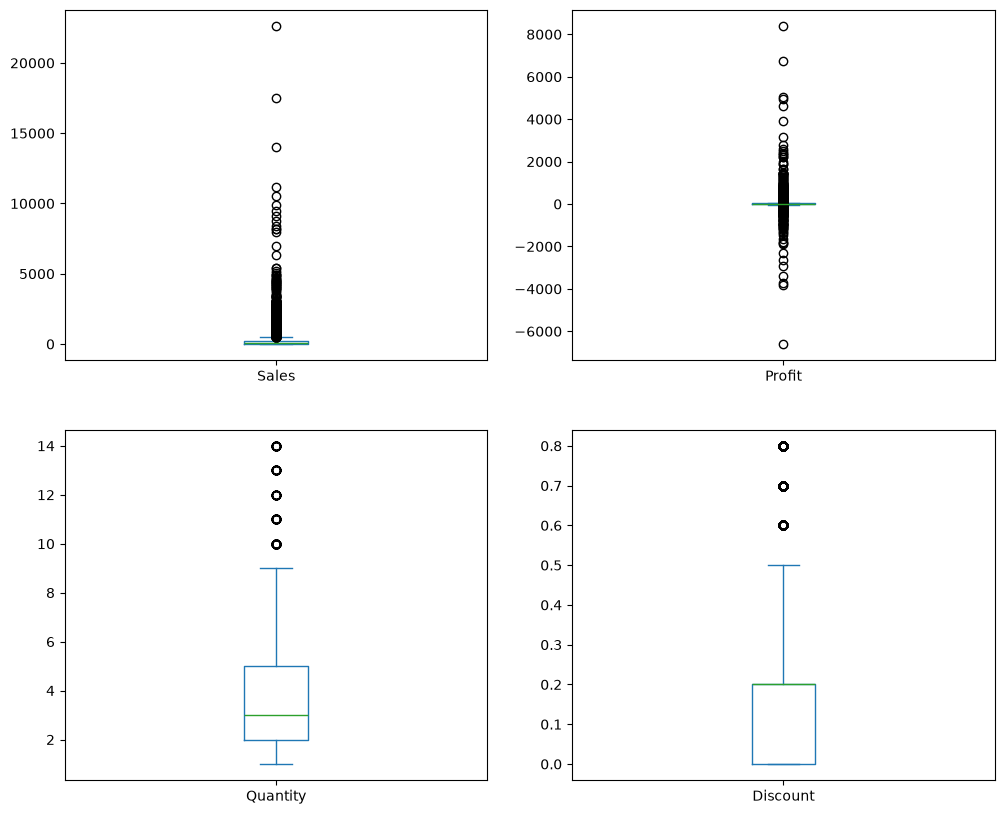

In [83]:
df[["Sales","Profit","Quantity","Discount"]].plot(
    kind="box",
    subplots=True,
    figsize=(12,10),
    layout=(2,2)
)

In [84]:
df.nlargest(15,"Sales")
df.nsmallest(15,"Profit")

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
7772,7773,CA-2016-108196,2016-11-25,2016-12-02,Standard Class,CS-12505,Cindy Stewart,Consumer,United States,Lancaster,...,43130,East,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.9780
683,684,US-2017-168116,2017-11-04,2017-11-04,Same Day,GT-14635,Grant Thornton,Corporate,United States,Burlington,...,27217,South,TEC-MA-10004125,Technology,Machines,Cubify CubeX 3D Printer Triple Head Print,7999.980,4,0.5,-3839.9904
9774,9775,CA-2014-169019,2014-07-26,2014-07-30,Standard Class,LF-17185,Luke Foster,Consumer,United States,San Antonio,...,78207,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,2177.584,8,0.8,-3701.8928
3011,3012,CA-2017-134845,2017-04-17,2017-04-23,Standard Class,SR-20425,Sharelle Roach,Home Office,United States,Louisville,...,80027,West,TEC-MA-10000822,Technology,Machines,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,0.7,-3399.9800
4991,4992,US-2017-122714,2017-12-07,2017-12-13,Standard Class,HG-14965,Henry Goldwyn,Corporate,United States,Chicago,...,60653,Central,OFF-BI-10001120,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,1889.990,5,0.8,-2929.4845
3151,3152,CA-2015-147830,2015-12-15,2015-12-18,First Class,NF-18385,Natalie Fritzler,Consumer,United States,Newark,...,43055,East,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,1799.994,2,0.7,-2639.9912
5310,5311,CA-2017-131254,2017-11-19,2017-11-21,First Class,NC-18415,Nathan Cano,Consumer,United States,Houston,...,77095,Central,OFF-BI-10003527,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,6,0.8,-2287.7820
9639,9640,CA-2015-116638,2015-01-28,2015-01-31,Second Class,JH-15985,Joseph Holt,Consumer,United States,Concord,...,28027,South,FUR-TA-10000198,Furniture,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,13,0.4,-1862.3124
1199,1200,CA-2016-130946,2016-04-08,2016-04-12,Standard Class,ZC-21910,Zuschuss Carroll,Consumer,United States,Houston,...,77041,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,1088.792,4,0.8,-1850.9464
2697,2698,CA-2014-145317,2014-03-18,2014-03-23,Standard Class,SM-20320,Sean Miller,Home Office,United States,Jacksonville,...,32216,South,TEC-MA-10002412,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784


In [85]:
df[(df["Discount"]==0.8)|(df["Discount"]==0.7)|(df["Discount"]==0.6)].sort_values("Discount",ascending=False)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
101,102,CA-2016-158568,2016-08-29,2016-09-02,Standard Class,RB-19465,Rick Bensley,Home Office,United States,Chicago,...,60610,Central,OFF-BI-10002609,Office Supplies,Binders,Avery Hidden Tab Dividers for Binding Systems,1.788,3,0.8,-3.0396
169,170,CA-2014-139892,2014-09-08,2014-09-12,Standard Class,BM-11140,Becky Martin,Consumer,United States,San Antonio,...,78207,Central,OFF-AP-10002518,Office Supplies,Appliances,Kensington 7 Outlet MasterPiece Power Center,177.980,5,0.8,-453.8490
14,15,US-2015-118983,2015-11-22,2015-11-26,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,...,76106,Central,OFF-AP-10002311,Office Supplies,Appliances,Holmes Replacement Filter for HEPA Air Cleaner...,68.810,5,0.8,-123.8580
15,16,US-2015-118983,2015-11-22,2015-11-26,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,...,76106,Central,OFF-BI-10000756,Office Supplies,Binders,Storex DuraTech Recycled Plastic Frosted Binders,2.544,3,0.8,-3.8160
174,175,US-2014-100853,2014-09-14,2014-09-19,Standard Class,JB-15400,Jennifer Braxton,Corporate,United States,Chicago,...,60623,Central,OFF-AP-10000891,Office Supplies,Appliances,Kensington 7 Outlet MasterPiece HOMEOFFICE Pow...,52.448,2,0.8,-131.1200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9591,9592,US-2016-105452,2016-07-28,2016-08-01,Standard Class,BF-11005,Barry Franz,Home Office,United States,Pasadena,...,77506,Central,FUR-FU-10003691,Furniture,Furnishings,"Eldon Image Series Desk Accessories, Ebony",24.700,5,0.6,-9.8800
9592,9593,US-2016-105452,2016-07-28,2016-08-01,Standard Class,BF-11005,Barry Franz,Home Office,United States,Pasadena,...,77506,Central,FUR-FU-10003806,Furniture,Furnishings,"Tenex Chairmat w/ Average Lip, 45"" x 53""",302.720,5,0.6,-378.4000
9747,9748,US-2014-140914,2014-11-11,2014-11-15,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Chicago,...,60653,Central,FUR-FU-10000175,Furniture,Furnishings,DAX Wood Document Frame.,10.984,2,0.6,-7.9634
9775,9776,CA-2014-169019,2014-07-26,2014-07-30,Standard Class,LF-17185,Luke Foster,Consumer,United States,San Antonio,...,78207,Central,FUR-FU-10004666,Furniture,Furnishings,DAX Clear Channel Poster Frame,17.496,3,0.6,-10.0602


Sales mein 1,167,Profit mein 1,881,Discount mein 856,Quantity mein 170, potential outliers identify hue.
Highest Sales transactions mein se kuch records negative profit generate kar rahe thay.
Largest losses Machines aur Binders subcategories mein observe hue.
70% aur 80% discount wale records mein significant negative profits observe hue.

Part 3

In [86]:
df['Year']=df["Order Date"].dt.year
df['Month']=df["Order Date"].dt.month
df['Quarter']=df["Order Date"].dt.quarter
df['Month Name']=df["Order Date"].dt.month_name()
df['Day of Week']=df["Order Date"].dt.day_name()
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Quarter,Month Name,Day of Week
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,4,November,Tuesday
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,4,November,Tuesday
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,2,June,Sunday
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,4,October,Sunday
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,4,October,Sunday


In [87]:
df['Shipping Duration']=df['Ship Date']-df['Order Date']
df["Shipping Duration"].dt.days
(df['Shipping Duration']==pd.Timedelta(0)).sum()     #there are 519 0-day deliveries
(df['Shipping Duration']<pd.Timedelta(0)).sum()    #there are 0 neagtive values

np.int64(0)

In [88]:
df['Profit Margin']=(df["Profit"]/df["Sales"])*100
df['Profit Margin'].describe()
(df['Profit Margin']>0).sum()   #Positve are 8058
(df['Profit Margin']<0).sum()   #Negative are 1871
(df['Profit Margin']==0).sum()  #Zeros are 65
df[df["Profit Margin"]==-275]   #4 found but these loss transactions are not actual monetary losses 

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Quantity,Discount,Profit,Year,Month,Quarter,Month Name,Day of Week,Shipping Duration,Profit Margin
261,262,US-2017-155299,2017-06-08,2017-06-12,Standard Class,Dl-13600,Dorris liebe,Corporate,United States,Pasadena,...,2,0.8,-4.466,2017,6,2,June,Thursday,4 days,-275.0
676,677,US-2017-119438,2017-03-18,2017-03-23,Standard Class,CD-11980,Carol Darley,Consumer,United States,Tyler,...,3,0.8,-7.392,2017,3,1,March,Saturday,5 days,-275.0
8766,8767,CA-2015-107083,2015-11-21,2015-11-27,Standard Class,BB-11545,Brenda Bowman,Corporate,United States,Fort Worth,...,3,0.8,-67.617,2015,11,4,November,Saturday,6 days,-275.0
9164,9165,CA-2015-164007,2015-06-08,2015-06-12,Standard Class,MG-17695,Maureen Gnade,Consumer,United States,Chicago,...,2,0.8,-393.602,2015,6,2,June,Monday,4 days,-275.0


In [89]:
(df["Quantity"]==0).sum()     #nothing found
df['Sales Per Unit']=df['Sales']/df["Quantity"]
df['Sales Per Unit'].head()
df['Sales Per Unit'].describe()
df.nlargest(5,"Sales Per Unit")
df.nsmallest(5,"Sales Per Unit")

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Discount,Profit,Year,Month,Quarter,Month Name,Day of Week,Shipping Duration,Profit Margin,Sales Per Unit
6818,6819,CA-2017-163860,2017-12-28,2018-01-01,Standard Class,LO-17170,Lori Olson,Corporate,United States,Peoria,...,0.8,-2.6880,2017,12,4,December,Thursday,4 days,-160.0,0.336
2427,2428,CA-2016-169922,2016-06-11,2016-06-17,Standard Class,MZ-17515,Mary Zewe,Corporate,United States,Arlington,...,0.8,-2.1504,2016,6,2,June,Saturday,6 days,-160.0,0.336
7791,7792,CA-2016-108364,2016-12-19,2016-12-24,Standard Class,BP-11050,Barry Pond,Corporate,United States,Chicago,...,0.8,-2.8800,2016,12,4,December,Monday,5 days,-160.0,0.360
1332,1333,CA-2014-122567,2014-02-16,2014-02-21,Standard Class,MN-17935,Michael Nguyen,Consumer,United States,Dallas,...,0.8,-1.7280,2014,2,1,February,Sunday,5 days,-160.0,0.360
1943,1944,CA-2017-144064,2017-08-29,2017-09-01,First Class,CP-12085,Cathy Prescott,Corporate,United States,Quincy,...,0.8,-5.1840,2017,8,3,August,Tuesday,3 days,-160.0,0.360


In [90]:
(df['Profit']==0).sum()   #having 65 values
df['Profitability Status']=df['Profit'].apply(
    lambda x:"Profit" if x>0
    else "Break-Even" if x==0 
    else 'Loss'
    )
# df[df["Profitability Status"]=="Brake-Even"]
# df[df["Profitability Status"]=="Loss"]
# df[df["Profitability Status"]=="Profit"]
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Profit,Year,Month,Quarter,Month Name,Day of Week,Shipping Duration,Profit Margin,Sales Per Unit,Profitability Status
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,41.9136,2016,11,4,November,Tuesday,3 days,16.00,130.9800,Profit
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,219.5820,2016,11,4,November,Tuesday,3 days,30.00,243.9800,Profit
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,6.8714,2016,6,2,June,Sunday,4 days,47.00,7.3100,Profit
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,-383.0310,2015,10,4,October,Sunday,7 days,-40.00,191.5155,Loss
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,2.5164,2015,10,4,October,Sunday,7 days,11.25,11.1840,Profit


In [91]:
df["Discount"].unique()         
df["Discount Bands"]=df['Discount'].apply(
    lambda x:"No Discount" if x==0
    else "Low" if (x>0) and (x<=0.2)
    else 'Medium' if (x>0.2) and (x<=0.5)
    else 'High' 
)
# df['Discount Bands']=pd.cut(df["Discount"],bins=[-0.1,0,0.2,0.5,0.8],labels=["No Discount","Low","Medium","High"])#pandas built-in method to do same thing
(df["Discount Bands"]=='No Discount').sum()   #4798 values
(df["Discount Bands"]=='Low').sum() #3803 values
(df["Discount Bands"]=='Medium').sum()  #537 values
(df["Discount Bands"]=='High').sum()    #856 values

np.int64(856)

Part 4

In [92]:
df[["Sales","Quantity","Discount","Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [93]:
df['Sales'].skew().round(1)  # 13  highly right-skewed
df['Profit'].skew().round(1)  # 7.6  highly right-skewed
df[["Sales","Profit"]].agg(["mean","median"])  
df.loc[df["Sales"].idxmax()]
df.loc[df["Profit"].idxmax()]     
df.loc[df["Sales"].idxmin()]    
df.loc[df["Profit"].idxmin()]   

Row ID                                                       7773
Order ID                                           CA-2016-108196
Order Date                                    2016-11-25 00:00:00
Ship Date                                     2016-12-02 00:00:00
Ship Mode                                          Standard Class
Customer ID                                              CS-12505
Customer Name                                       Cindy Stewart
Segment                                                  Consumer
Country                                             United States
City                                                    Lancaster
State                                                        Ohio
Postal Code                                                 43130
Region                                                       East
Product ID                                        TEC-MA-10000418
Category                                               Technology
Sub-Catego

In [94]:
df['Region'].value_counts()   
df["Region"].value_counts(normalize=True)*100   
df['Category'].value_counts()   
df["Category"].value_counts(normalize=True)*100  
df['Segment'].value_counts()   
df["Segment"].value_counts(normalize=True)*100  
df['Ship Mode'].value_counts()  
df["Ship Mode"].value_counts(normalize=True)*100 

Ship Mode
Standard Class    59.715829
Second Class      19.461677
First Class       15.389234
Same Day           5.433260
Name: proportion, dtype: float64

In [95]:
df[["Sales","Quantity","Discount","Profit"]].corr()

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


Part 5

Key Performance Indicator

In [96]:
Tsales=df['Sales'].sum()   
Tprofit=df['Profit'].sum()  
Tquantity=df['Quantity'].sum() 
df["Order ID"].nunique() 
(df['Profit'].sum()/df['Sales'].sum())*100    

np.float64(12.467217240315605)

In [97]:
df["Sales"].mean()    
df.groupby(df["Order ID"])["Sales"].sum().mean() 
df.loc[df['Sales'].idxmax()]   
df.loc[df['Sales'].idxmin()]  
df.groupby(df["Order ID"])["Sales"].sum().idxmax()   
df.groupby(df["Order ID"])["Sales"].sum().idxmin()   

'CA-2017-124114'

In [98]:
count=df['Profitability Status'].value_counts()   
status_wise_sales=df.groupby(df["Profitability Status"])["Sales"].sum()
status_wise_sales    
sales_contribution=(df.groupby(df["Profitability Status"])["Sales"].sum()
                    /df['Sales'].sum()
                    *100
)
sales_contribution      
status_wise_profit=df.groupby(df["Profitability Status"])["Profit"].sum()
status_wise_profit  
pd.DataFrame(
    {"Count":count,
    'Sales':status_wise_sales,
    'Sales%':sales_contribution,
    "Profit/Loss":status_wise_profit
})

,Count,Sales,Sales%,Profit/Loss
Profitability Status,,,,
Break-Even,65,2.768685e+04,1.205243,0.0000
Loss,1871,4.687072e+05,20.403403,-156131.2857
Profit,8058,1.800807e+06,78.391354,442528.3074


In [99]:
df.nlargest(15,'Sales')    
#High-sale transactions with medium discount also result in losses.
#Some high-sales transactions also generate substantial profits.
#High sales do not always guarantee profitability,as some high-sales transactions have negative profit margins.

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Year,Month,Quarter,Month Name,Day of Week,Shipping Duration,Profit Margin,Sales Per Unit,Profitability Status,Discount Bands
2697,2698,CA-2014-145317,2014-03-18,2014-03-23,Standard Class,SM-20320,Sean Miller,Home Office,United States,Jacksonville,...,2014,3,1,March,Tuesday,5 days,-8.000000,3773.080,Loss,Medium
6826,6827,CA-2016-118689,2016-10-02,2016-10-09,Standard Class,TC-20980,Tamara Chand,Corporate,United States,Lafayette,...,2016,10,4,October,Sunday,7 days,48.000000,3499.990,Profit,No Discount
8153,8154,CA-2017-140151,2017-03-23,2017-03-25,First Class,RB-19360,Raymond Buch,Consumer,United States,Seattle,...,2017,3,1,March,Thursday,2 days,48.000000,3499.990,Profit,No Discount
2623,2624,CA-2017-127180,2017-10-22,2017-10-24,First Class,TA-21385,Tom Ashbrook,Home Office,United States,New York City,...,2017,10,4,October,Sunday,2 days,35.000000,2799.992,Profit,Low
4190,4191,CA-2017-166709,2017-11-17,2017-11-22,Standard Class,HL-15040,Hunter Lopez,Consumer,United States,Newark,...,2017,11,4,November,Friday,5 days,48.000000,3499.990,Profit,No Discount
9039,9040,CA-2016-117121,2016-12-17,2016-12-21,Standard Class,AB-10105,Adrian Barton,Consumer,United States,Detroit,...,2016,12,4,December,Saturday,4 days,50.000000,760.980,Profit,No Discount
4098,4099,CA-2014-116904,2014-09-23,2014-09-28,Standard Class,SC-20095,Sanjit Chand,Consumer,United States,Minneapolis,...,2014,9,3,September,Tuesday,5 days,49.000000,1889.990,Profit,No Discount
4277,4278,US-2016-107440,2016-04-16,2016-04-20,Standard Class,BS-11365,Bill Shonely,Corporate,United States,Lakewood,...,2016,4,2,April,Saturday,4 days,26.000000,1299.990,Profit,No Discount
8488,8489,CA-2016-158841,2016-02-02,2016-02-04,Second Class,SE-20110,Sanjit Engle,Consumer,United States,Arlington,...,2016,2,1,February,Tuesday,2 days,32.000000,1749.990,Profit,No Discount
6425,6426,CA-2016-143714,2016-05-23,2016-05-27,Standard Class,CC-12370,Christopher Conant,Consumer,United States,Philadelphia,...,2016,5,2,May,Monday,4 days,13.333333,2099.994,Profit,Medium


Part 6

In [100]:
Top_10_revenue_products=df.groupby(df["Product Name"])["Sales"].sum().sort_values(ascending=False).head(10)
df.groupby(df["Product Name"])["Quantity"].sum().sort_values(ascending=False).head(10)
df.groupby(df["Product Name"])["Profit"].sum().sort_values(ascending=False).head(10)
df.groupby(df["Product Name"])["Profit"].sum().sort_values(ascending=True).head(10)
Total_category_sales=df.groupby("Category")["Sales"].sum()
Total_category_profit=df.groupby("Category")["Profit"].sum()
Total_category_quantity=df.groupby("Category")["Quantity"].sum()
Category_Profit_Margin=(Total_category_profit/Total_category_sales)*100
Category_Revenue_Share=(df.groupby("Category")["Sales"].sum()
                    /df['Sales'].sum()
                    *100
)
pd.DataFrame(
    {'Sales':Total_category_sales,
    'Profit':Total_category_profit,
    "Quantity":Total_category_quantity,
    "Category Profit Margin":Category_Profit_Margin,
    "Category Revenue Share":Category_Revenue_Share
})
Total_sub_category_sales=df.groupby("Sub-Category")["Sales"].sum()
Total_sub_category_profit=df.groupby("Sub-Category")["Profit"].sum()
Total_sub_category_quantity=df.groupby("Sub-Category")["Quantity"].sum()
Average_sub_category_discount=df.groupby("Sub-Category")["Discount"].mean()*100
pd.DataFrame(
    {'Sales':Total_sub_category_sales,
    'Profit':Total_sub_category_profit,
    "Quantity":Total_sub_category_quantity,
    "Average Discount":Average_sub_category_discount
})
Total_sub_category_profit.sort_values(ascending=False) #profit wise most selled product in sub_category:copiers:55617.8249
Total_sub_category_sales.sort_values(ascending=False) #Sales wise most selled product in sub_category:phones:330007.054
Total_sub_category_quantity.sort_values(ascending=False) #quantity wise most selled product in sub_category:blinders:5974

Sub-Category
Binders        5974
Paper          5178
Furnishings    3563
Phones         3289
Storage        3158
Art            3000
Accessories    2976
Chairs         2356
Appliances     1729
Labels         1400
Tables         1241
Fasteners       914
Envelopes       906
Bookcases       868
Supplies        647
Machines        440
Copiers         234
Name: Quantity, dtype: int64

Part 7

In [101]:
df["Customer ID"].nunique()   #793
df.groupby("Customer ID")['Sales'].sum().sort_values(ascending=False).head(10)
df.groupby("Customer ID")['Profit'].sum().sort_values(ascending=False).head(10)
df.groupby("Customer ID")['Order ID'].nunique().sort_values(ascending=False).head(10)

Customer ID
EP-13915    17
SH-19975    13
NS-18640    13
PG-18820    13
ZC-21910    13
EA-14035    13
JE-15745    13
CK-12205    13
AH-10690    12
RB-19465    12
Name: Order ID, dtype: int64

In [102]:
Total_segment_sales=df.groupby("Segment")["Sales"].sum()
Total_segment_profit=df.groupby("Segment")["Profit"].sum()
Total_segment_quantity=df.groupby("Segment")["Quantity"].sum()
Segment_Profit_Margin=(Total_segment_profit/Total_segment_sales)*100
pd.DataFrame({
    "Sales":Total_segment_sales,
    "Profit":Total_segment_profit,
    "Quantity":Total_segment_quantity,
    "Segment Profit Margin":Segment_Profit_Margin
})

,Sales,Profit,Quantity,Segment Profit Margin
Segment,,,,
Consumer,1.161401e+06,134119.2092,19521,11.548050
Corporate,7.061464e+05,91979.1340,11608,13.025506
Home Office,4.296531e+05,60298.6785,6744,14.034269


In [103]:
Total_region_sales=df.groupby("Region")["Sales"].sum()
Total_region_profit=df.groupby("Region")["Profit"].sum()
Total_region_quantity=df.groupby("Region")["Quantity"].sum()
Region_Profit_Margin=(Total_region_profit/Total_region_sales)*100
pd.DataFrame({
    "Sales":Total_region_sales,
    "Profit":Total_region_profit,
    "Quantity":Total_region_quantity,
    "Region Profit Margin":Region_Profit_Margin
})
Total_state_sales=df.groupby("State")["Sales"].sum().nlargest(10)
Total_state_profit=df.groupby("State")["Profit"].sum().nsmallest(10)
Total_city_sales=df.groupby("City")["Sales"].sum().nlargest(10)
Total_city_profit=df.groupby("City")["Profit"].sum().nsmallest(10)
df['Ship Mode'].value_counts() 
df["Shipping Duration"].mean() 
df.groupby("Ship Mode")['Sales'].sum().round(1)
df.groupby("Ship Mode")['Profit'].sum()

Ship Mode
First Class        48969.8399
Same Day           15891.7589
Second Class       57446.6354
Standard Class    164088.7875
Name: Profit, dtype: float64

In [104]:
Total_Discount_band_Sales=df.groupby('Discount Bands')["Sales"].sum()
Total_Discount_band_Profit=df.groupby('Discount Bands')["Profit"].sum()
Total_Discount_band_Margin=(Total_Discount_band_Profit/Total_Discount_band_Sales)*100
pd.DataFrame({
    "Sales":Total_Discount_band_Sales,
    "Profit":Total_Discount_band_Profit,
    "Margin":Total_Discount_band_Margin
})
df[df['Profit']<0].groupby("Discount Bands").size()

Discount Bands
High      856
Low       523
Medium    492
dtype: int64

Part 8

In [105]:
Dates_sum=df.groupby(df['Order Date'])[['Sales','Profit']].sum()
Best_Dates_Sales_Profit=Dates_sum.idxmax() #s:2014-03-18,p:2016-10-02
Best_Dates_Sales_Profit
Worst_Dates_Sales_Profit=Dates_sum.idxmin() #s:2015-07-19,p:2016-11-25
Worst_Dates_Sales_Profit
Month_of_Year_sum=df.groupby(["Year","Month"])[['Sales','Profit',"Quantity"]].sum()
Month_of_Year_sum.reset_index()
Yearly_Sales_Sum=df.groupby('Year')['Sales'].sum()
Yearly_Profit_Sum=df.groupby('Year')['Profit'].sum()
Yearly_Margin=(Yearly_Profit_Sum/Yearly_Sales_Sum)*100
pd.DataFrame({
    "Sales":Yearly_Sales_Sum,
    "Profit":Yearly_Profit_Sum,
    "Margin":Yearly_Margin
}) #min:2014-01-03,max:2017-12-30,years=4
Quarterly_Sales_Profit_Sum=df.groupby(['Year',"Quarter"])[['Sales',"Profit"]].sum()
Quarterly_Sales_Profit_Sum.reset_index()

,Year,Quarter,Sales,Profit
0,2014,1,74447.7960,3811.2290
1,2014,2,86538.7596,11204.0692
2,2014,3,143633.2123,12804.7218
3,2014,4,179627.7302,21723.9541
4,2015,1,68851.7386,9264.9416
5,2015,2,89124.1870,12190.9224
6,2015,3,130259.5752,16853.6194
7,2015,4,182297.0082,23309.1203
8,2016,1,93237.1810,11441.3708
9,2016,2,136082.3010,16390.3394


In [106]:
previous_m=Month_of_Year_sum['Sales'].shift(1)
current_m=Month_of_Year_sum['Sales']
MOM=(current_m-previous_m)/previous_m*100
MOM.where(previous_m!=0)
previous_y=Yearly_Sales_Sum.shift(1)
current_y=Yearly_Sales_Sum
YOY=(current_y-previous_y)/previous_y*100
YOY.where(previous_y!=0)

Year
2014          NaN
2015    -2.832227
2016    29.471521
2017    20.355962
Name: Sales, dtype: float64

In [107]:
Month_of_Year_sum[['Sales','Profit']].idxmax()  #s:(2017,11),p:(2016,12)
Month_of_Year_sum[['Sales','Profit']].idxmin()  #s:(2014,2),p:(2015,1)
Yearly_Sales_Sum.idxmax() #2017
Yearly_Sales_Sum.idxmin() #2015
Yearly_Profit_Sum.idxmax() #2017
Yearly_Profit_Sum.idxmin() #2014
MOM.idxmax() #(2014,3) 1132.131
MOM.idxmin() #(2016,1) -75.250
YOY.idxmax() #2016 29.4715
YOY.idxmin() #2015 -2.832

np.int32(2015)

In [108]:
Month_of_Year_sum['Sales'].unstack()
Quarterly_Sales_Profit_Sum['Sales'].unstack()

Quarter,1,2,3,4
Year,,,,
2014,74447.7960,86538.7596,143633.2123,179627.7302
2015,68851.7386,89124.1870,130259.5752,182297.0082
2016,93237.1810,136082.3010,143787.3622,236098.7538
2017,123144.8602,133764.3720,196251.9560,280054.0670


Part 9

[Text(0, 0, '742000'), Text(0, 0, '719047'), Text(0, 0, '836154')]

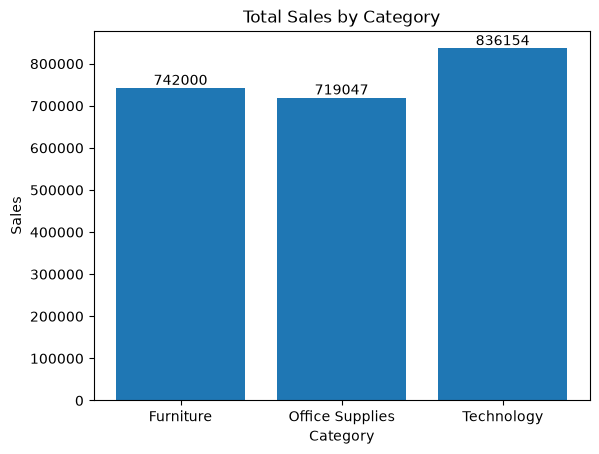

In [109]:
# ax=Total_category_sales.plot(kind="bar")   
# plt.bar_label(ax.containers[0])
ax=plt.bar(Total_category_sales.index,Total_category_sales.values)
plt.xlabel("Category")
plt.ylabel("Sales")
plt.title("Total Sales by Category")
plt.bar_label(ax)

Text(0.5, 1.0, 'Top Products')

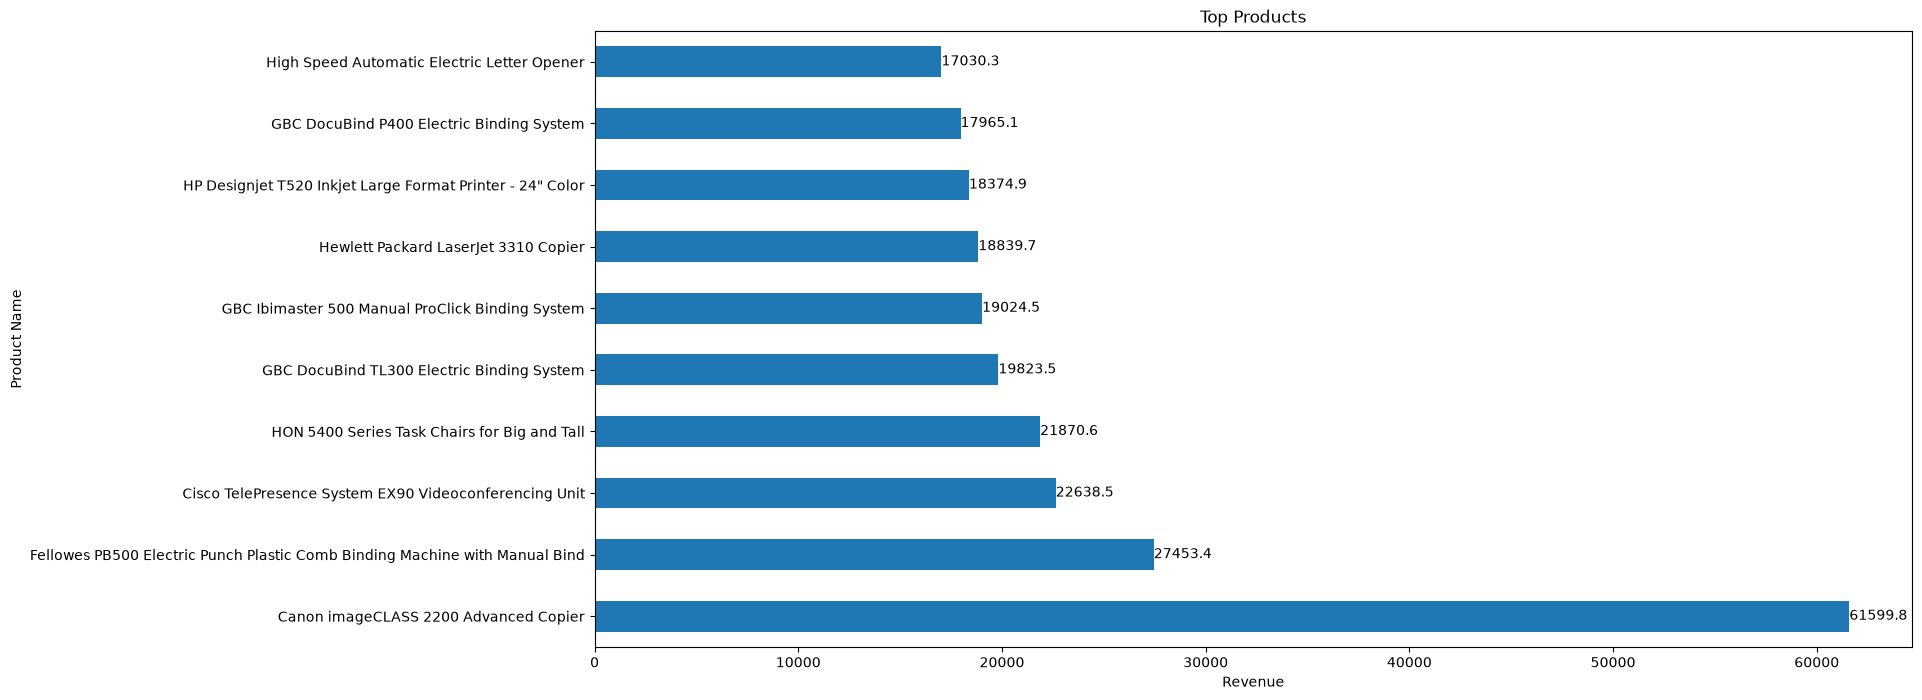

In [110]:
ax=Top_10_revenue_products.plot(kind="barh",figsize=[17,8])
plt.bar_label(ax.containers[0])
plt.xlabel("Revenue")
plt.ylabel("Product Name")
plt.title("Top Products")

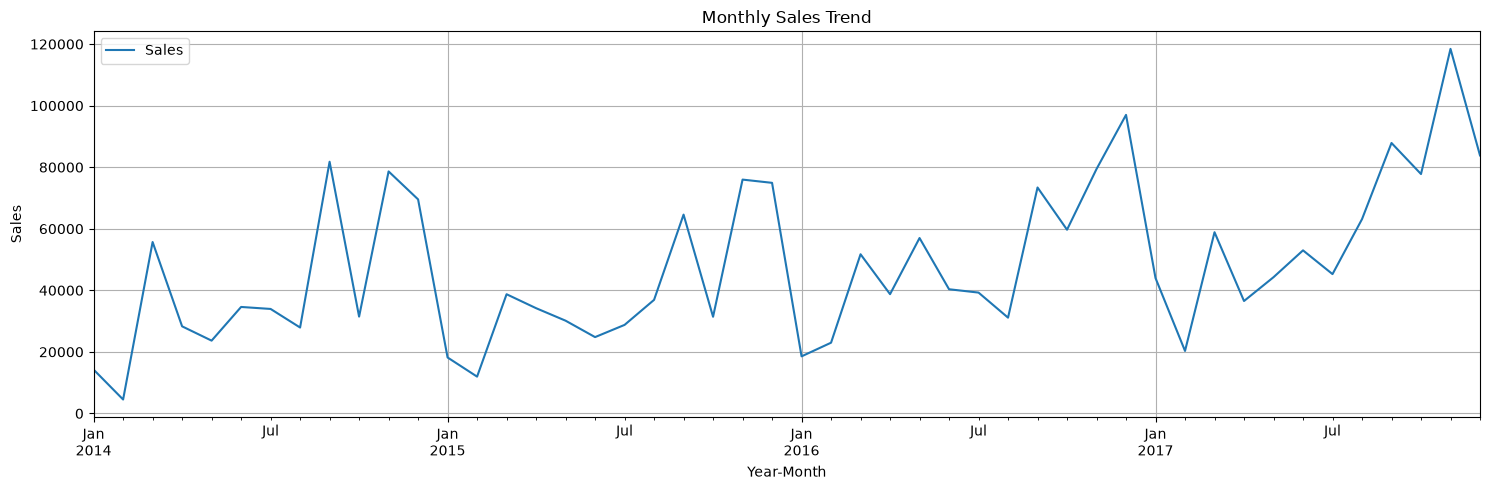

In [111]:
temp=Month_of_Year_sum.reset_index()
temp['Year_Month']=pd.to_datetime(temp['Year'].astype(str)+"-"+temp['Month'].astype(str)+"-"+"01")
temp.plot(
    x='Year_Month',
    y='Sales',
    figsize=[15,5],
    kind='line',
    title="Monthly Sales Trend",
    xlabel="Year-Month",
    ylabel="Sales"
    )
plt.grid()
plt.tight_layout()

Text(0.5, 1.0, 'Category Revenue Share')

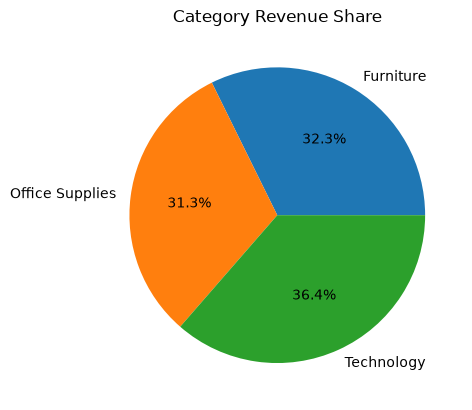

In [112]:
plt.pie(Total_category_sales.values,labels=Total_category_sales.index,autopct='%1.1f%%')
plt.title("Category Revenue Share")

Text(0, 0.5, 'Profit')

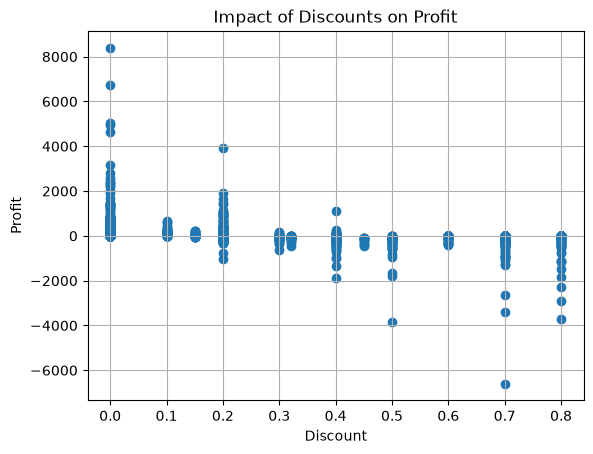

In [113]:
plt.scatter(df['Discount'],df['Profit'])
plt.grid()
plt.title('Impact of Discounts on Profit')
plt.xlabel("Discount")
plt.ylabel("Profit")

Part 10

(0.0, 1000.0)

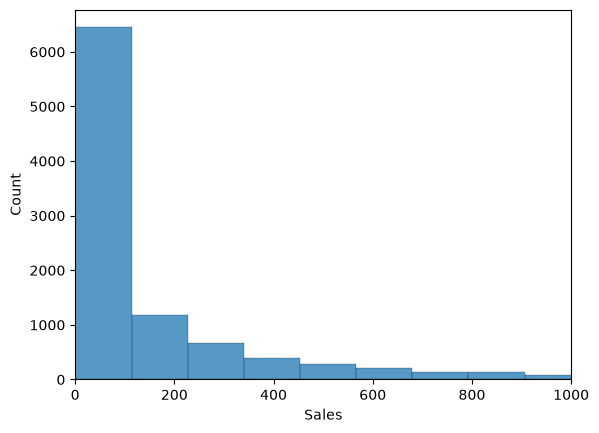

In [114]:
sns.histplot(data=df,x='Sales')
plt.xlim(0,1000)

<Axes: xlabel='Profit', ylabel='Density'>

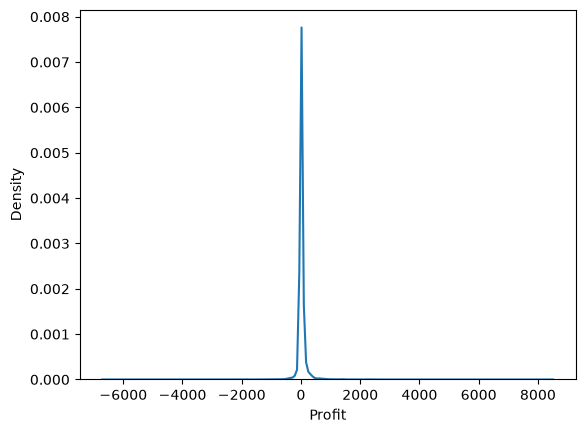

In [115]:
sns.kdeplot(data=df,x=df['Profit'])

<Axes: xlabel='Category', ylabel='Profit'>

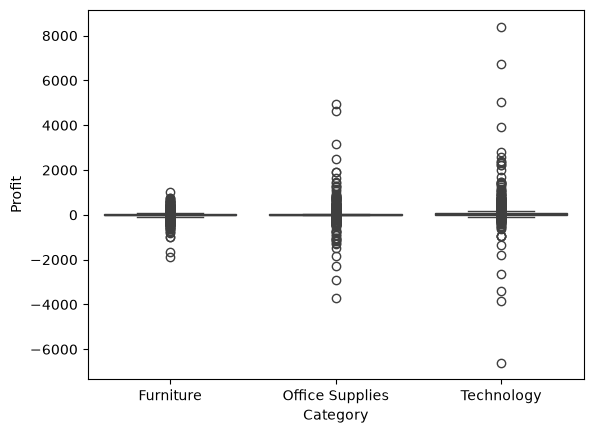

In [116]:
sns.boxplot(df,x=df['Category'],y=df['Profit'])

<Axes: xlabel='Ship Mode', ylabel='count'>

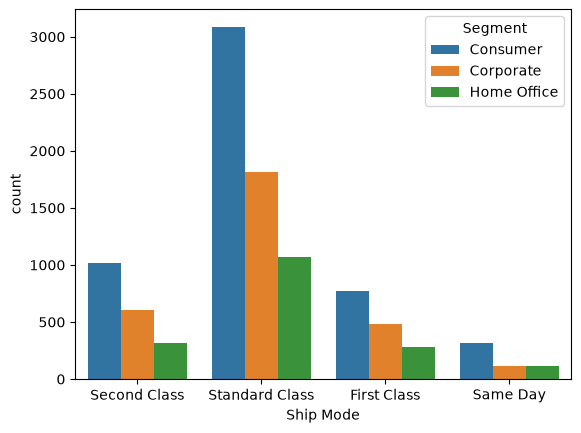

In [117]:
sns.countplot(data=df,x=df['Ship Mode'],hue=df['Segment'])

<Axes: xlabel='Category', ylabel='Sales'>

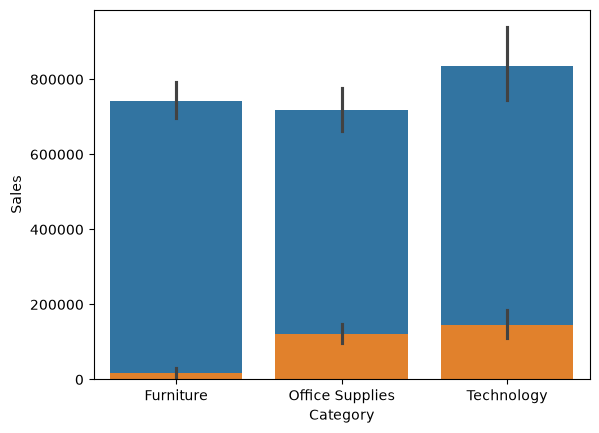

In [118]:
sns.barplot(data=df,x='Category',y='Sales',estimator=sum)
sns.barplot(data=df,x='Category',y='Profit',estimator=sum)

<Axes: >

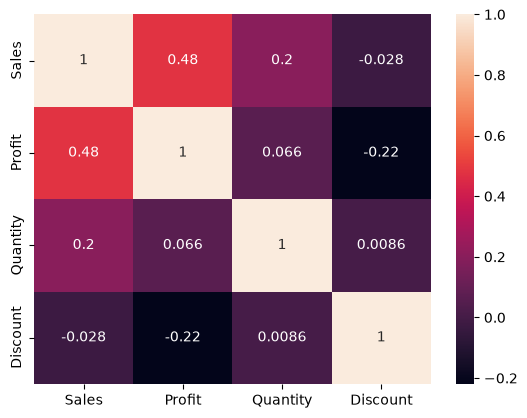

In [119]:
corr=df[['Sales','Profit','Quantity','Discount']].corr()
sns.heatmap(corr,annot=True)

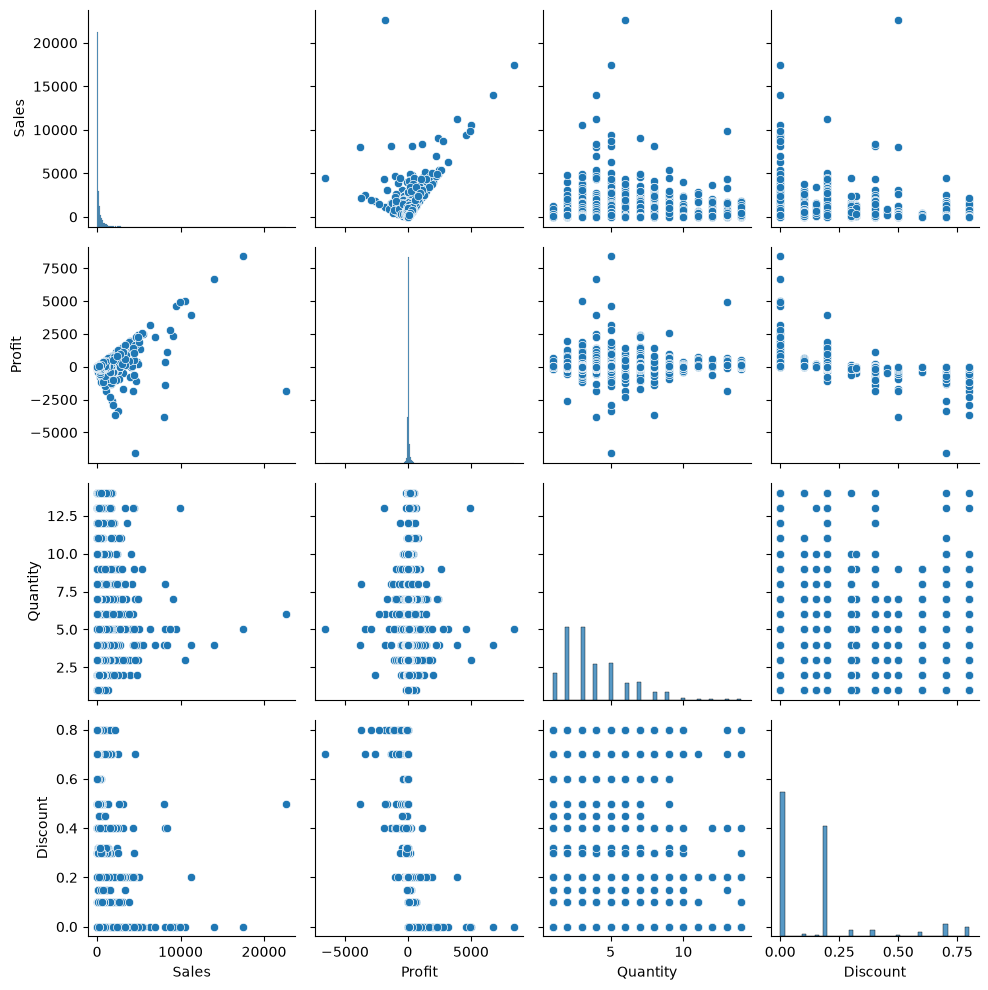

In [120]:
sns.pairplot(data=df[["Sales","Profit",'Quantity','Discount']])
plt.tight_layout()

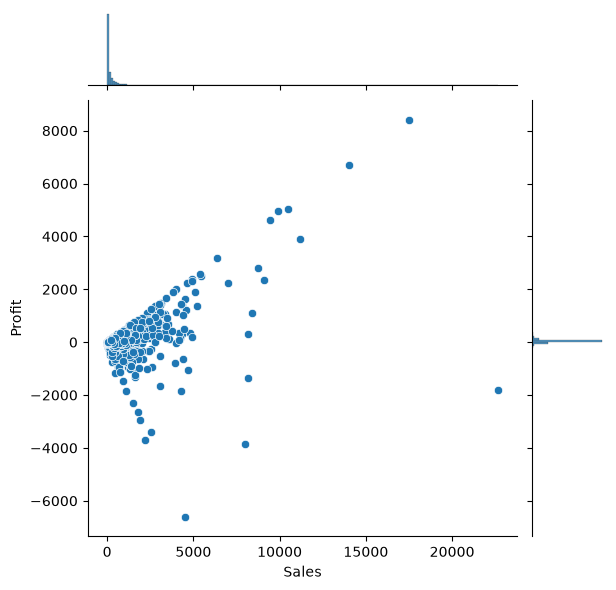

In [121]:
sns.jointplot(data=df, x="Sales", y="Profit")

Part 11

In [7]:
bar=df.groupby(['Category','Sub-Category'])[['Sales','Profit']].sum().reset_index()
px.bar(bar,x='Sub-Category',y=['Sales','Profit'],hover_data=["Category"])

In [123]:
fig=px.line(temp,x='Year_Month',y=['Sales','Profit'])
fig.update_xaxes(dtick="M1")

In [124]:
fig = px.pie(df, names='Category', values='Sales')
fig.update_traces(
    hovertemplate='Category:%{label}<br>Percentage:%{percent}<br>Sales:%{value}'   
)
 #tech:36.4,furn:32.3,office:31.3
#hover method to display customly

In [125]:
px.scatter(df,'Sales',"Profit",color='Category',size='Quantity') #zayada sale,prof,quant tech ki ha then furn,off respective

In [126]:
px.sunburst(bar,path=['Category','Sub-Category'],values='Sales')

In [127]:
px.treemap(bar,path=['Category','Sub-Category'],values='Sales',color="Sales")

In [131]:
df.to_csv("../data/superstore_processed.csv", index=False)